In [1]:
!pip install -q imagecodecs tifffile
import os, re, glob, zipfile, urllib.request, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from scipy import ndimage as ndi
import tifffile

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
URL = "http://data.celltrackingchallenge.net/training-datasets/PhC-C2DH-U373.zip"
ZIP = "PhC-C2DH-U373.zip"
DATA_ROOT = "PhC-C2DH-U373"

if not os.path.isdir(DATA_ROOT):
    if not os.path.exists(ZIP):
        print("Downloading...")
        urllib.request.urlretrieve(URL, ZIP)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(".")
print(sorted(os.listdir(DATA_ROOT)))

Downloading...
['01', '01_ERR_SEG', '01_GT', '01_ST', '02', '02_ERR_SEG', '02_GT', '02_ST']


In [3]:
def frame_id(path):
    return int(re.findall(r"(\d+)\.tif$", path)[-1])

def load_sequence(seq):
    masks = sorted(glob.glob(f"{DATA_ROOT}/{seq}_GT/SEG/*.tif"))
    imgs, labs = [], []
    for m in masks:
        idx = frame_id(m)
        img = tifffile.imread(f"{DATA_ROOT}/{seq}/t{idx:03d}.tif").astype(np.float32)
        lab = tifffile.imread(m).astype(np.int32)
        imgs.append(img); labs.append(lab)
    return imgs, labs

imgs1, labs1 = load_sequence("01")
imgs2, labs2 = load_sequence("02")
print("annotated frames: seq 01 =", len(imgs1), "| seq 02 =", len(imgs2))
all_imgs, all_labs = imgs1 + imgs2, labs1 + labs2

# annotated frames are sparse (far apart in time), so a random split is acceptable
perm = np.random.RandomState(SEED).permutation(len(all_imgs))
n_val = max(4, int(0.2 * len(perm)))
va_idx, tr_idx = perm[:n_val], perm[n_val:]
tr_imgs = [all_imgs[i] for i in tr_idx]; tr_labs = [all_labs[i] for i in tr_idx]
va_imgs = [all_imgs[i] for i in va_idx]; va_labs = [all_labs[i] for i in va_idx]
print(len(tr_imgs), "train /", len(va_imgs), "val images | shape:", tr_imgs[0].shape,
      "| value range:", tr_imgs[0].min(), tr_imgs[0].max())

annotated frames: seq 01 = 15 | seq 02 = 19
28 train / 6 val images | shape: (520, 696) | value range: 30.0 183.0


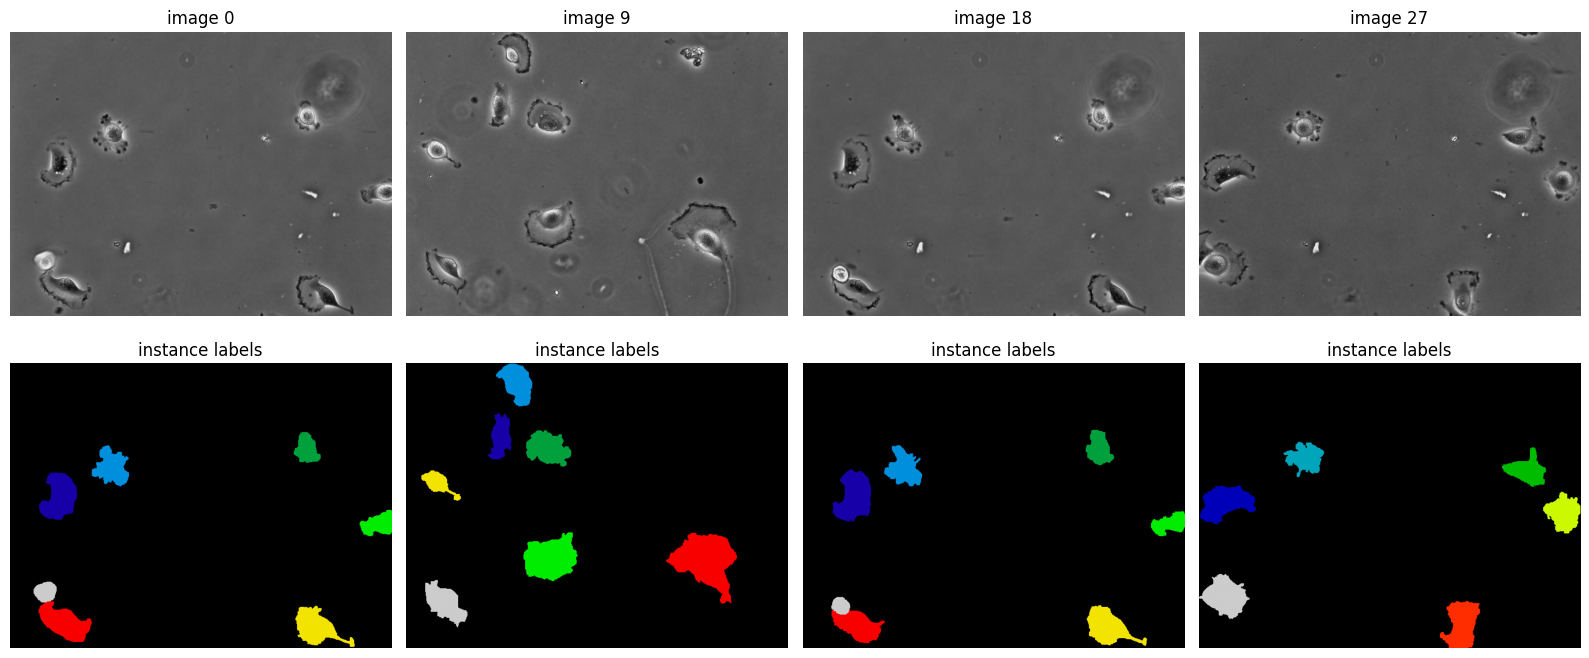

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for j, i in enumerate(np.linspace(0, len(tr_imgs) - 1, 4).astype(int)):
    ax[0, j].imshow(tr_imgs[i], cmap="gray"); ax[0, j].set_title(f"image {i}"); ax[0, j].axis("off")
    ax[1, j].imshow(tr_labs[i], cmap="nipy_spectral"); ax[1, j].set_title("instance labels"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

Prepared in 3.7s


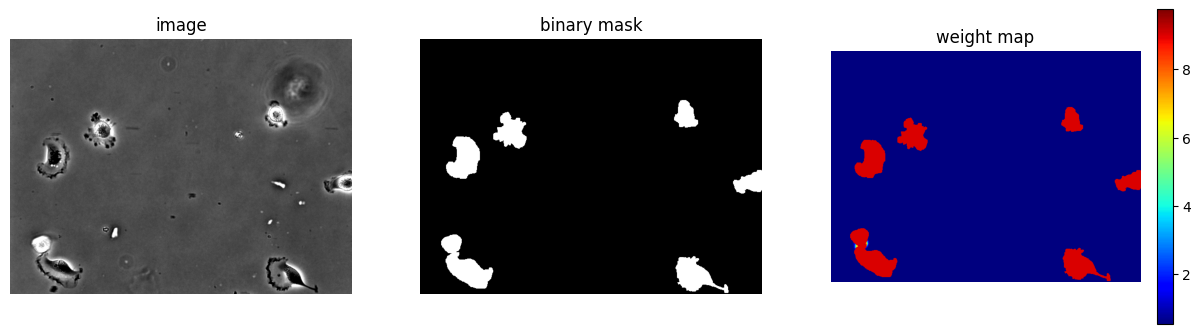

In [5]:
def normalize(img):
    lo, hi = np.percentile(img, 0.5), np.percentile(img, 99.5)
    return np.clip((img - lo) / (hi - lo + 1e-8), 0, 1).astype(np.float32)

def make_weight_map(lab, w0=10.0, sigma=5.0):
    fg = (lab > 0).astype(np.float32)
    # class balancing
    wc = np.empty_like(fg)
    f1 = fg.mean()
    wc[fg == 1] = 0.5 / max(f1, 1e-6)
    wc[fg == 0] = 0.5 / max(1 - f1, 1e-6)
    ids = [i for i in np.unique(lab) if i != 0]
    if len(ids) >= 2:
        dists = np.stack([ndi.distance_transform_edt(lab != i) for i in ids], axis=0)
        dists.sort(axis=0)
        d1, d2 = dists[0], dists[1]
        border = w0 * np.exp(-((d1 + d2) ** 2) / (2 * sigma ** 2)) * (fg == 0)
    else:
        border = np.zeros_like(fg)
    return (wc + border).astype(np.float32)

def prepare(imgs, labs):
    X = [normalize(i) for i in imgs]
    Y = [(l > 0).astype(np.int64) for l in labs]
    W = [make_weight_map(l) for l in labs]
    return X, Y, W

t0 = time.time()
Xtr, Ytr, Wtr = prepare(tr_imgs, tr_labs)
Xva, Yva, Wva = prepare(va_imgs, va_labs)
print(f"Prepared in {time.time()-t0:.1f}s")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(Xtr[0], cmap="gray"); ax[0].set_title("image")
ax[1].imshow(Ytr[0], cmap="gray"); ax[1].set_title("binary mask")
im = ax[2].imshow(Wtr[0], cmap="jet"); ax[2].set_title("weight map"); plt.colorbar(im, ax=ax[2], fraction=0.046)
for a in ax: a.axis("off")
plt.show()

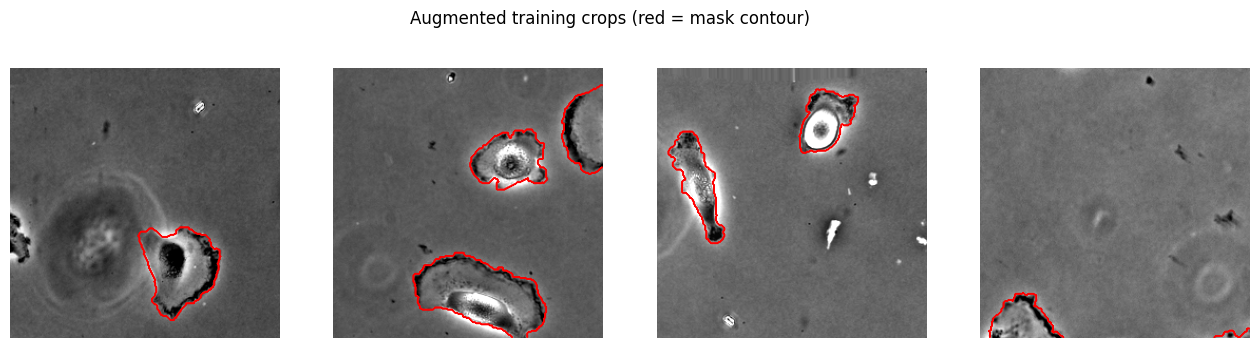

In [6]:
CROP = 256

def elastic_deform(img, mask, wmap, grid=3, sigma=10):
    h, w = img.shape
    dx = np.random.randn(grid, grid) * sigma
    dy = np.random.randn(grid, grid) * sigma
    dx = ndi.zoom(dx, (h / grid, w / grid), order=3)[:h, :w]
    dy = ndi.zoom(dy, (h / grid, w / grid), order=3)[:h, :w]
    yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    coords = [np.clip(yy + dy, 0, h - 1), np.clip(xx + dx, 0, w - 1)]
    img2 = ndi.map_coordinates(img, coords, order=3, mode="reflect")
    mask2 = ndi.map_coordinates(mask.astype(np.float32), coords, order=0, mode="reflect")
    w2 = ndi.map_coordinates(wmap, coords, order=1, mode="reflect")
    return img2, mask2.astype(np.int64), w2

class CellDataset(Dataset):
    def __init__(self, X, Y, W, train=True, n_per_epoch=200):
        self.X, self.Y, self.W, self.train, self.n = X, Y, W, train, n_per_epoch
    def __len__(self): return self.n if self.train else len(self.X)
    def __getitem__(self, i):
        if not self.train:
            return self._pad(self.X[i], self.Y[i], self.W[i])
        k = np.random.randint(len(self.X))
        x, y, w = self.X[k], self.Y[k], self.W[k]
        x, y, w = elastic_deform(x, y, w)
        # random crop
        h, wd = x.shape
        r, c = np.random.randint(0, h - CROP + 1), np.random.randint(0, wd - CROP + 1)
        x, y, w = x[r:r+CROP, c:c+CROP], y[r:r+CROP, c:c+CROP], w[r:r+CROP, c:c+CROP]
        # flips + rot90
        if np.random.rand() < 0.5: x, y, w = x[:, ::-1], y[:, ::-1], w[:, ::-1]
        if np.random.rand() < 0.5: x, y, w = x[::-1], y[::-1], w[::-1]
        k90 = np.random.randint(4)
        x, y, w = np.rot90(x, k90), np.rot90(y, k90), np.rot90(w, k90)
        # gray value variation
        x = np.clip(x * np.random.uniform(0.9, 1.1) + np.random.uniform(-0.05, 0.05), 0, 1)
        return (torch.from_numpy(np.ascontiguousarray(x)).float()[None],
                torch.from_numpy(np.ascontiguousarray(y)).long(),
                torch.from_numpy(np.ascontiguousarray(w)).float())
    def _pad(self, x, y, w):
        h, wd = x.shape
        ph, pw = (-h) % 16, (-wd) % 16
        x = np.pad(x, ((0, ph), (0, pw)), mode="reflect")
        y = np.pad(y, ((0, ph), (0, pw)), mode="constant")
        w = np.pad(w, ((0, ph), (0, pw)), mode="constant")
        return torch.from_numpy(x).float()[None], torch.from_numpy(y).long(), torch.from_numpy(w).float()

train_dl = DataLoader(CellDataset(Xtr, Ytr, Wtr, True, 200), batch_size=4, shuffle=False, num_workers=2,
                      worker_init_fn=lambda i: np.random.seed(SEED + i + int(time.time()) % 1000))
val_dl = DataLoader(CellDataset(Xva, Yva, Wva, False), batch_size=1, shuffle=False)

xb, yb, wb = next(iter(train_dl))
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for j in range(4):
    ax[j].imshow(xb[j, 0], cmap="gray"); ax[j].contour(yb[j], colors="r", linewidths=0.6); ax[j].axis("off")
plt.suptitle("Augmented training crops (red = mask contour)"); plt.show()

In [7]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=2, base=64):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]
        self.enc1, self.enc2 = DoubleConv(in_ch, c[0]), DoubleConv(c[0], c[1])
        self.enc3, self.enc4 = DoubleConv(c[1], c[2]), DoubleConv(c[2], c[3])
        self.bott = DoubleConv(c[3], c[4])
        self.pool = nn.MaxPool2d(2)
        self.up4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, 2), DoubleConv(c[4], c[3])
        self.up3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, 2), DoubleConv(c[3], c[2])
        self.up2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, 2), DoubleConv(c[2], c[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, 2), DoubleConv(c[1], c[0])
        self.drop = nn.Dropout2d(0.5)          # dropout at end of contracting path (paper, Sec. 3.1)
        self.head = nn.Conv2d(c[0], n_classes, 1)
        for m in self.modules():               # He init: std = sqrt(2/N)
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu"); nn.init.zeros_(m.bias)
    def forward(self, x):
        e1 = self.enc1(x); e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2)); e4 = self.enc4(self.pool(e3))
        b = self.drop(self.bott(self.pool(e4)))
        d4 = self.dec4(torch.cat([self.up4(b), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.head(d1)

model = UNet().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")
print("Output shape:", model(torch.zeros(1, 1, 256, 256, device=device)).shape)

Parameters: 31.0M
Output shape: torch.Size([1, 2, 256, 256])


In [8]:
def weighted_ce(logits, target, wmap):
    ce = F.cross_entropy(logits, target, reduction="none")
    return (ce * wmap).sum() / wmap.sum()

@torch.no_grad()
def evaluate(model, dl):
    model.eval(); ious, dices = [], []
    for x, y, w in dl:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(1)
        inter = ((pred == 1) & (y == 1)).sum().item()
        union = ((pred == 1) | (y == 1)).sum().item()
        ious.append(inter / max(union, 1))
        dices.append(2 * inter / max(pred.sum().item() + y.sum().item(), 1))
    return float(np.mean(ious)), float(np.mean(dices))

In [9]:
EPOCHS = 40
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
hist = {"loss": [], "val_iou": [], "val_dice": []}
best_iou = 0.0

for ep in range(1, EPOCHS + 1):
    model.train(); run, t0 = 0.0, time.time()
    for x, y, w in train_dl:
        x, y, w = x.to(device), y.to(device), w.to(device)
        opt.zero_grad()
        loss = weighted_ce(model(x), y, w)
        loss.backward(); opt.step()
        run += loss.item()
    sched.step()
    iou, dice = evaluate(model, val_dl)
    hist["loss"].append(run / len(train_dl)); hist["val_iou"].append(iou); hist["val_dice"].append(dice)
    if iou > best_iou:
        best_iou = iou; torch.save(model.state_dict(), "unet_phc_u373_best.pt")
    print(f"Epoch {ep:02d}/{EPOCHS} | loss {hist['loss'][-1]:.4f} | val IoU {iou:.4f} | val Dice {dice:.4f} | {time.time()-t0:.0f}s")
print("Best val IoU:", round(best_iou, 4))

Epoch 01/40 | loss 0.5852 | val IoU 0.3658 | val Dice 0.5342 | 43s
Epoch 02/40 | loss 0.2469 | val IoU 0.3689 | val Dice 0.5374 | 42s
Epoch 03/40 | loss 0.2365 | val IoU 0.3181 | val Dice 0.4813 | 42s
Epoch 04/40 | loss 0.7430 | val IoU 0.4787 | val Dice 0.6468 | 43s
Epoch 05/40 | loss 0.4548 | val IoU 0.2836 | val Dice 0.4403 | 41s
Epoch 06/40 | loss 0.5624 | val IoU 0.4625 | val Dice 0.6310 | 42s
Epoch 07/40 | loss 0.3802 | val IoU 0.4307 | val Dice 0.6001 | 42s
Epoch 08/40 | loss 0.2471 | val IoU 0.5143 | val Dice 0.6775 | 42s
Epoch 09/40 | loss 0.1832 | val IoU 0.4167 | val Dice 0.5868 | 42s
Epoch 10/40 | loss 0.1450 | val IoU 0.5226 | val Dice 0.6850 | 42s
Epoch 11/40 | loss 0.1044 | val IoU 0.5502 | val Dice 0.7085 | 41s
Epoch 12/40 | loss 0.1062 | val IoU 0.5153 | val Dice 0.6790 | 41s
Epoch 13/40 | loss 0.0909 | val IoU 0.6326 | val Dice 0.7737 | 42s
Epoch 14/40 | loss 0.0815 | val IoU 0.5841 | val Dice 0.7359 | 42s
Epoch 15/40 | loss 0.0883 | val IoU 0.7271 | val Dice 0.8409 |

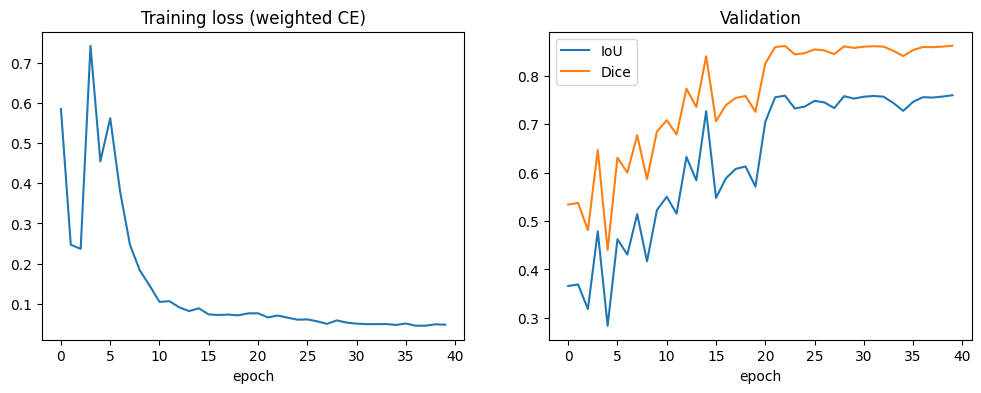

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["loss"]); ax[0].set_title("Training loss (weighted CE)"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["val_iou"], label="IoU"); ax[1].plot(hist["val_dice"], label="Dice")
ax[1].set_title("Validation"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

## 9. Qualitative results (validation images)

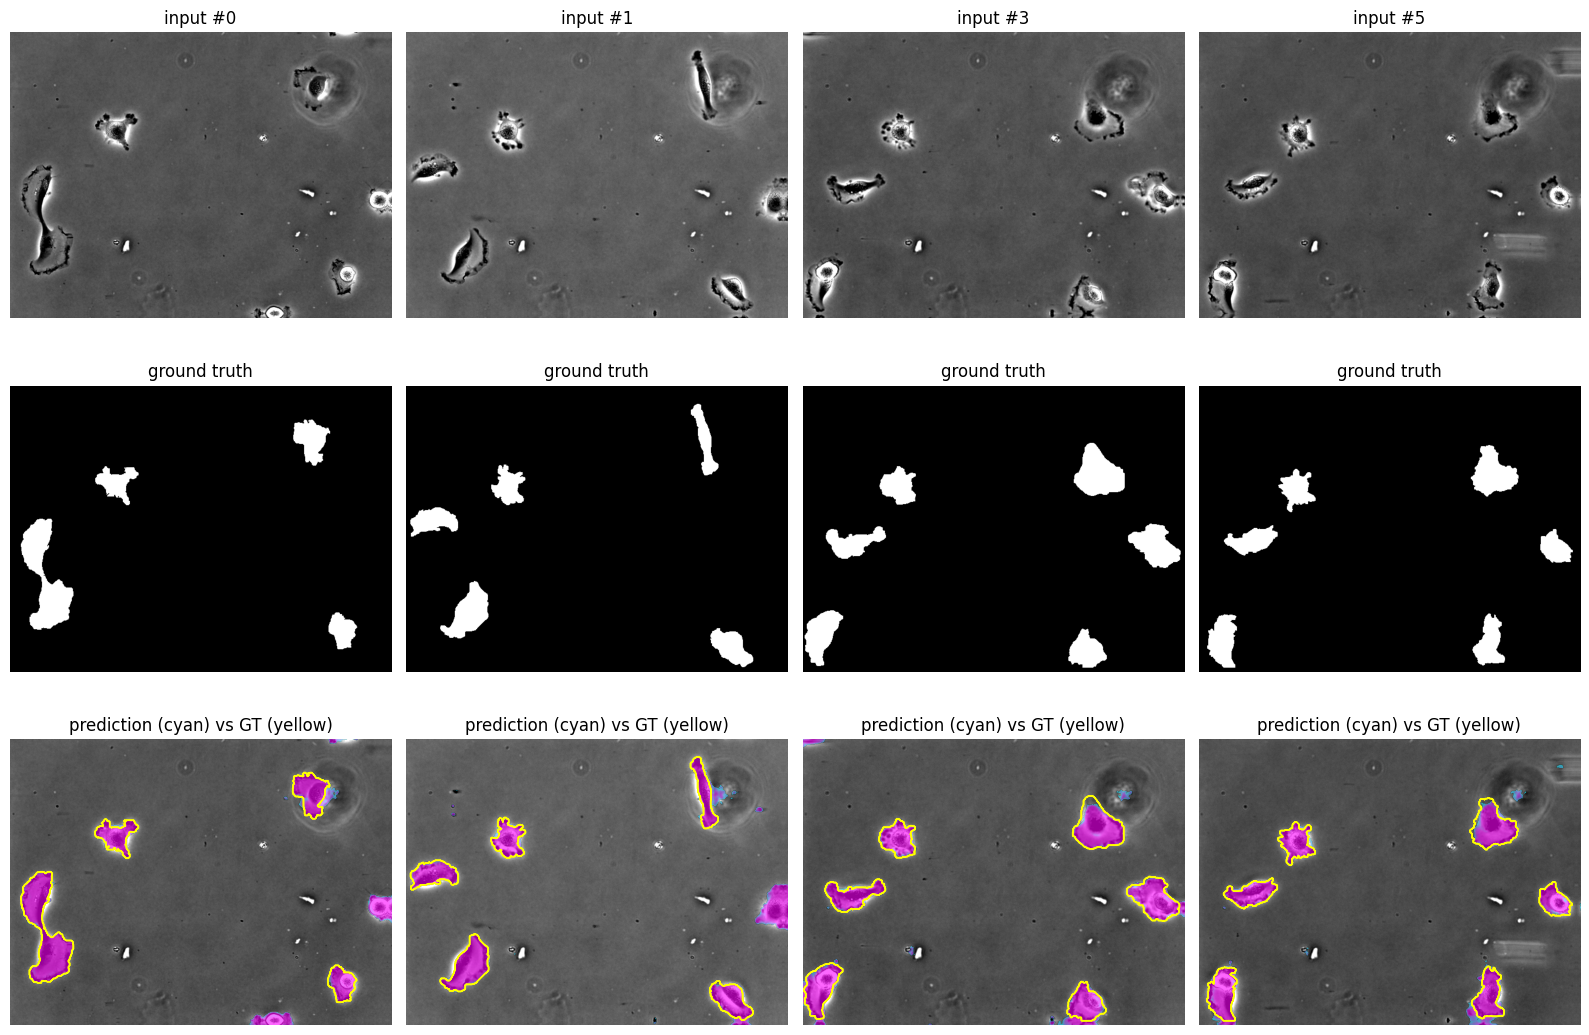

In [11]:
model.load_state_dict(torch.load("unet_phc_u373_best.pt", map_location=device)); model.eval()
idxs = np.linspace(0, len(Xva) - 1, 4).astype(int)
fig, ax = plt.subplots(3, 4, figsize=(16, 11))
for j, i in enumerate(idxs):
    x, y, _ = val_dl.dataset[i]
    with torch.no_grad():
        prob = F.softmax(model(x[None].to(device)), 1)[0, 1].cpu().numpy()
    ax[0, j].imshow(x[0], cmap="gray"); ax[0, j].set_title(f"input #{i}")
    ax[1, j].imshow(y, cmap="gray"); ax[1, j].set_title("ground truth")
    ax[2, j].imshow(x[0], cmap="gray"); ax[2, j].imshow(np.ma.masked_less(prob, 0.5), cmap="cool", alpha=0.6)
    ax[2, j].contour(y, colors="yellow", linewidths=0.8); ax[2, j].set_title("prediction (cyan) vs GT (yellow)")
    for r in range(3): ax[r, j].axis("off")
plt.tight_layout(); plt.show()

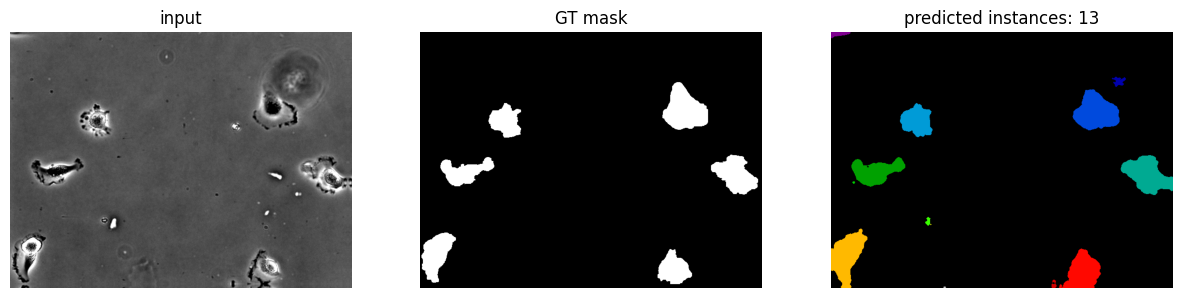

In [12]:
x, y, _ = val_dl.dataset[len(Xva)//2]
with torch.no_grad():
    pred = model(x[None].to(device)).argmax(1)[0].cpu().numpy()
pred = ndi.binary_opening(pred, iterations=1)
inst, n = ndi.label(pred)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(x[0], cmap="gray"); ax[0].set_title("input")
ax[1].imshow(y, cmap="gray"); ax[1].set_title("GT mask")
ax[2].imshow(inst, cmap="nipy_spectral"); ax[2].set_title(f"predicted instances: {n}")
for a in ax: a.axis("off")
plt.show()